# Agentic AI for Autonomous Investment Research

## Planner and Agent Orchestration with Real Specialists

The Planner creates a validated research plan; the Orchestrator routes only selected work and grants each specialist only its planned tools. Market and earnings calculations are deterministic. News runs as an explicit five-stage prompt chain and keeps every intermediate result.

Groq and Hugging Face API clients are the default. Leave `LLM_PROVIDER` unset to select a configured Groq client first, then Hugging Face; set `LLM_PROVIDER=local` only to opt into the optional local Qwen backend. Add credentials to a local `.env` file (see `.env.example`).

The integration status table distinguishes real implementations from placeholders and unimplemented Engineer 3 report/memory handoffs. Educational research only; not personalized investment advice.

In [14]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

for module_name in list(sys.modules):
    if module_name == 'src' or module_name.startswith('src.'):
        del sys.modules[module_name]

try:
    import truststore
    truststore.inject_into_ssl()
except ImportError:
    pass

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.bootstrap import build_runtime
from src.orchestration_viz import (
    plan_table, routing_table, tool_log_table, execution_table,
    plot_plan, plot_routing_matrix, plot_execution_timeline, plot_tool_calls,
)

pd.set_option('display.max_colwidth', 90)
pd.set_option('display.width', 160)

rt = build_runtime(allow_stubs=False)
print('LLM provider:', rt.llm.provider, '| model:', rt.llm.model)
print('Integration status (real, stub, or missing):')
display(pd.Series(rt.integration, name='status').to_frame())

LLM provider: Groq | model: openai/gpt-oss-120b
Integration status (real, stub, or missing):


,status
memory,missing
market_agent,real
earnings_agent,real
news_agent,real
data_tools,real
llm,Groq
report_pipeline,missing


## 1. Planning

A broad request produces a plan that covers every specialist.

Planner mode: llm | scope: comprehensive
Intent      : Provide comprehensive investment research for MSFT
Rationale   : The question requests a full investment analysis, so all three specialized subagents are required to cover market performance, financial fundamentals, and recent news.


,step,subagent,description,depends_on,tools,completion_criteria,status
0,S1,market_agent,"Gather price and benchmark history, compute performance metrics, and retrieve macro se...",-,"get_price_history, get_benchmark_history, get_macro_series","Price history and benchmark data retrieved, performance metrics calculated, and macro ...",pending
1,S2,earnings_agent,"Retrieve financial statements and analyze income statement, balance sheet, cash flow, ...",-,"get_financial_statements, get_sec_filings",Financial statements downloaded and key financial ratios and risk metrics computed.,pending
2,S3,news_agent,"Collect recent company news, identify catalysts and risks, and produce a source‑backed...",-,get_company_news,Recent news items gathered and summarized with identified catalysts and risks.,pending


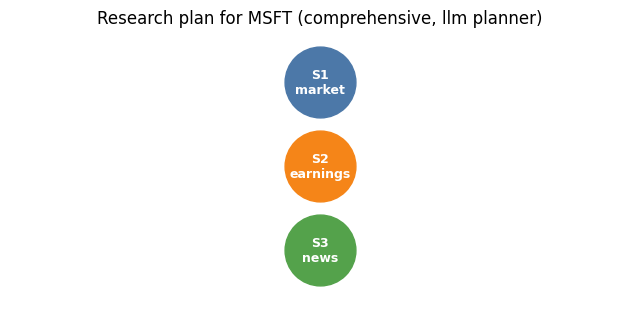

In [12]:
state = rt.orchestrator.plan('MSFT', 'Produce comprehensive investment research')
print('Planner mode:', state.plan.planner_mode, '| scope:', state.plan.scope)
print('Intent      :', state.plan.intent)
print('Rationale   :', state.plan.rationale)
display(plan_table(state.plan))
plot_plan(state.plan)
plt.show()
for w in state.warnings:
    print('WARNING:', w.source, '-', w.message)

Each step has a concrete completion criterion and the exact tools the subagent may call. The plan is validated (known subagents, allowed tools, unique ids, no dependency cycles) before anything runs.

## 2. Routing: narrow questions select narrow sets

Five questions, including a multi-subagent route with a dependency (earnings must precede the price-reaction analysis) and a macro question that adds an optional tool.

Analyze one-year price performance
   S1 market_agent: tools=['get_price_history', 'get_benchmark_history']
Analyze revenue and margin trends
   S1 earnings_agent: tools=['get_financial_statements']
Summarize recent product announcements
   S1 news_agent: tools=['get_company_news']
Analyze earnings and the resulting share-price movement
   S1 earnings_agent: tools=['get_financial_statements']
   S2 market_agent (after S1): tools=['get_price_history', 'get_benchmark_history']
Analyze price performance given interest rates and inflation
   S1 market_agent: tools=['get_price_history', 'get_benchmark_history', 'get_macro_series']
Produce comprehensive investment research
   S1 market_agent: tools=['get_price_history', 'get_benchmark_history']
   S2 earnings_agent: tools=['get_financial_statements']
   S3 news_agent: tools=['get_company_news']


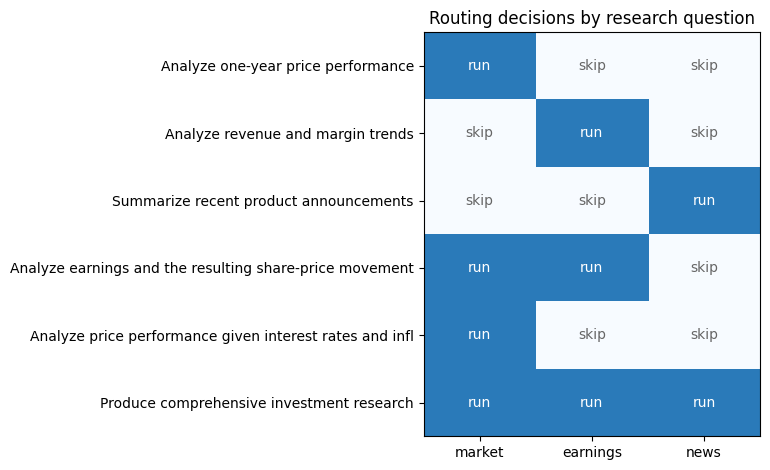

In [3]:
QUESTIONS = [
    'Analyze one-year price performance',
    'Analyze revenue and margin trends',
    'Summarize recent product announcements',
    'Analyze earnings and the resulting share-price movement',
    'Analyze price performance given interest rates and inflation',
    'Produce comprehensive investment research',
]

cases = {}
for q in QUESTIONS:
    s = rt.orchestrator.plan('AAPL', q)
    cases[q] = s.routing_log
    print(f'{q}')
    for step in s.plan.steps:
        dep = f' (after {", ".join(step.depends_on)})' if step.depends_on else ''
        print(f'   {step.step_id} {step.subagent}{dep}: tools={step.tools}')

plot_routing_matrix(cases, rt.subagents.names())
plt.show()

In [4]:
# Selected AND skipped subagents, each with a reason and confidence.
display(routing_table(cases[QUESTIONS[3]]))
display(routing_table(cases[QUESTIONS[0]]))

,decision,subagent,task,reason,confidence,status
0,SELECTED,earnings_agent,"Analyze AAPL revenue, profit, margin and cash-flow trends from financial statements",Question mentions: earnings.,0.7,pending
1,SELECTED,market_agent,"Analyze AAPL price performance against the benchmark: returns, rolling volatility and ...","Question mentions: movement, price, share-price.",0.9,pending
2,skipped,news_agent,none,"The question does not ask about recent news, events or announcements.",0.8,pending


,decision,subagent,task,reason,confidence,status
0,SELECTED,market_agent,"Analyze AAPL price performance against the benchmark: returns, rolling volatility and ...",Question mentions: price.,0.7,pending
1,skipped,earnings_agent,none,"The question does not ask about revenue, profit, margins, cash flow or financial state...",0.8,pending
2,skipped,news_agent,none,"The question does not ask about recent news, events or announcements.",0.8,pending


The matrix shows routing is conditional: the number of selected subagents changes with the question, so this is not a fixed pipeline. The optional macro tool appears only for the macro question.

## 3. Lessons from earlier runs shape the plan

The Planner receives lessons from Memory (Engineer 3) as guidance, never as evidence. The lesson below is a hand-written stand-in to show the mechanism; real lessons come from run reflection.

In [5]:
lesson = [{
    'memory_id': 'DEMO-1',
    'lesson': 'Price-only answers lacked event context; include recent news.',
    'score': 0.9,
    'hint': {'require_subagents': ['news_agent'], 'extra_criteria': 'state data limitations explicitly'},
}]
q = 'Analyze one-year price performance'
before = rt.planner.create_plan('AAPL', q)
after = rt.planner.create_plan('AAPL', q, lesson)
print('Without lesson:', before.plan.selected_subagents)
print('With lesson   :', after.plan.selected_subagents, '| lessons applied:', after.plan.lessons_applied)
display(routing_table(after.routing))

Without lesson: ['market_agent']
With lesson   : ['market_agent', 'news_agent'] | lessons applied: ['DEMO-1']


,decision,subagent,task,reason,confidence,status
0,SELECTED,market_agent,"Analyze AAPL price performance against the benchmark: returns, rolling volatility and ...",Question mentions: price.,0.7,pending
1,SELECTED,news_agent,"Summarize recent AAPL news through the five-stage prompt chain: events, catalysts and ...",Added by lesson DEMO-1: Price-only answers lacked event context; include recent news.,0.7,pending
2,skipped,earnings_agent,none,"The question does not ask about revenue, profit, margins, cash flow or financial state...",0.8,pending


## 4. Orchestration and Dynamic Tool Use

The Orchestrator runs steps in dependency order. Each subagent gets a tool session limited to the tools in its plan step; every call is logged with status, duration and a result summary.

,step_id,subagent,status,started_at,duration_ms,tools_allowed,tool_calls,message
0,S1,earnings_agent,success,2026-10-11T09:16:17+00:00,0.08,[get_financial_statements],1,[STUB] earnings_agent executed 1/1 planned tool calls; no analysis performed.
1,S2,market_agent,success,2026-10-11T09:16:17+00:00,0.09,"[get_price_history, get_benchmark_history]",2,[STUB] market_agent executed 2/2 planned tool calls; no analysis performed.


,caller,tool_name,status,duration_ms,output_summary,error,retrieved_at
0,orchestrator,get_company_profile,success,0.0,dict with 3 keys,None,2026-10-11T09:16:17+00:00
1,earnings_agent,get_financial_statements,success,0.0,dict with 3 keys,None,2026-10-11T09:16:17+00:00
2,market_agent,get_price_history,success,0.0,dict with 3 keys,None,2026-10-11T09:16:17+00:00
3,market_agent,get_benchmark_history,success,0.0,dict with 3 keys,None,2026-10-11T09:16:17+00:00


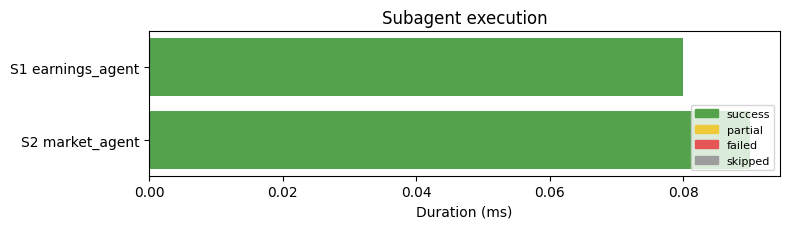

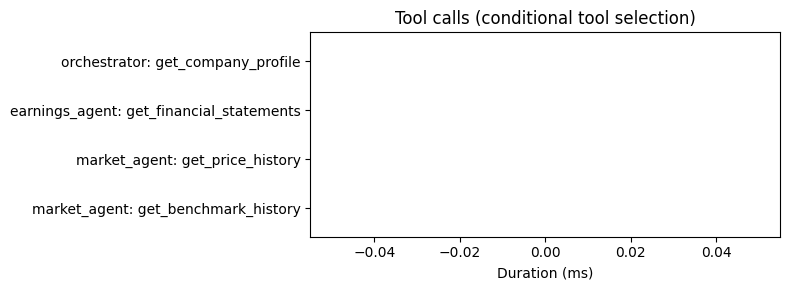

Subagents that ran: ['earnings_agent', 'market_agent']
News tool called?   False


In [13]:
state = rt.orchestrator.run('MSFT', 'Analyze earnings and the resulting share-price movement')
display(execution_table(state))
display(tool_log_table(state))
plot_execution_timeline(state)
plt.show()
plot_tool_calls(state)
plt.show()
print('Subagents that ran:', state.selected_subagents)
print('News tool called?  ', any(c['tool_name'] == 'get_company_news' for c in state.tool_call_log))

## 5. Real Specialist Outputs and News Prompt Chain

Run a comprehensive request to execute the real market, earnings, and news specialists. The chart payloads and each news-chain stage remain available in the aggregated state; missing feeds or model credentials appear as partial coverage.

,step_id,subagent,status,started_at,duration_ms,tools_allowed,tool_calls,message
0,S1,market_agent,success,2026-10-11T19:12:54+00:00,1805.55,"[get_price_history, get_benchmark_history, get_macro_series]",3,"MSFT returned +5.6% from 2025-10-10 to 2026-10-09 against +20.5% for SPY, with 32.8% a..."
1,S2,earnings_agent,success,2026-10-11T19:12:55+00:00,2660.14,"[get_financial_statements, get_sec_filings]",2,"For the fiscal year ended 2026-06-30, MSFT reported revenue of USD 331.8 bn (+17.8% ye..."
2,S3,news_agent,success,2026-10-11T19:12:58+00:00,74323.83,[get_company_news],1,Microsoft is confronting a series of regulatory setbacks as the Trump administration s...


,caller,tool_name,status,duration_ms,output_summary,error,retrieved_at
0,orchestrator,get_company_profile,success,3192.44,dict with 13 keys,None,2026-10-11T19:12:54+00:00
1,market_agent,get_price_history,success,327.78,"DataFrame shape=(251, 5)",None,2026-10-11T19:12:54+00:00
2,market_agent,get_benchmark_history,success,289.92,"DataFrame shape=(251, 5)",None,2026-10-11T19:12:54+00:00
3,market_agent,get_macro_series,success,1170.78,"DataFrame shape=(248, 1)",None,2026-10-11T19:12:55+00:00
4,earnings_agent,get_financial_statements,success,238.40,"DataFrame shape=(4, 9)",None,2026-10-11T19:12:56+00:00
5,earnings_agent,get_sec_filings,success,2410.97,"DataFrame shape=(4, 4)",None,2026-10-11T19:12:58+00:00
6,news_agent,get_company_news,success,1668.41,dict with 5 keys,None,2026-10-11T19:13:00+00:00


Coverage: {'market_agent': 'success', 'earnings_agent': 'success', 'news_agent': 'success'}
Company profile: Microsoft Corporation | Technology | USD
Finding evidence references resolve: True | unresolved: []


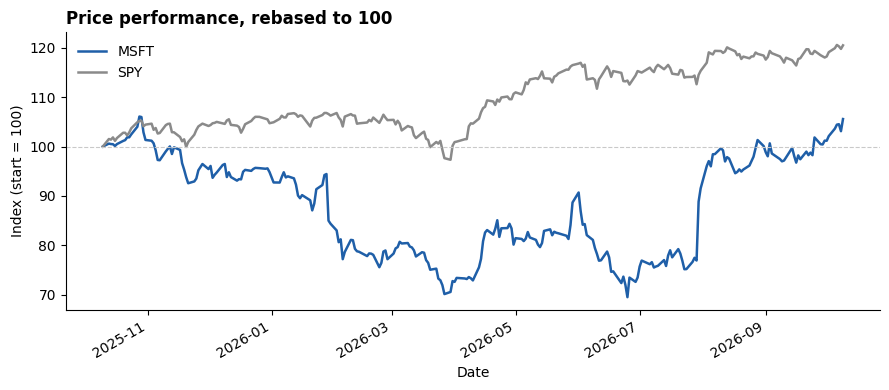

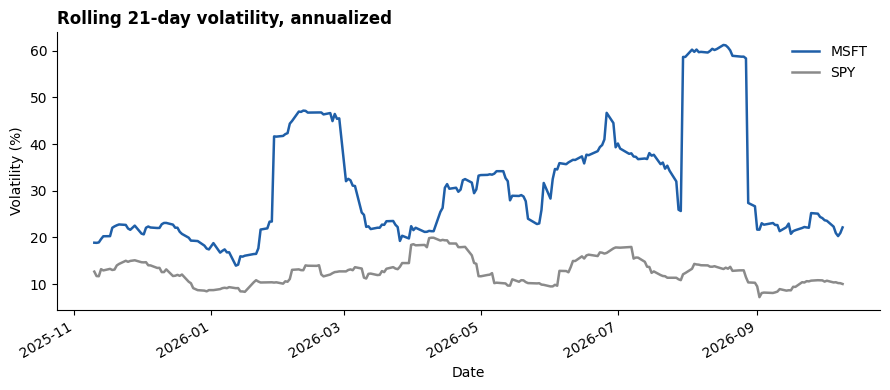

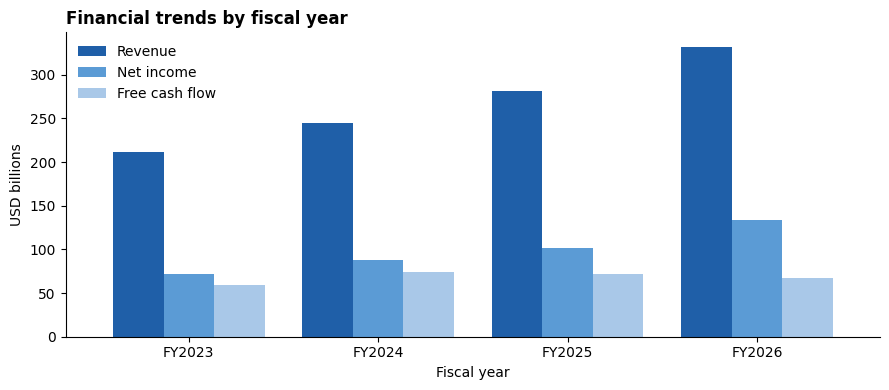

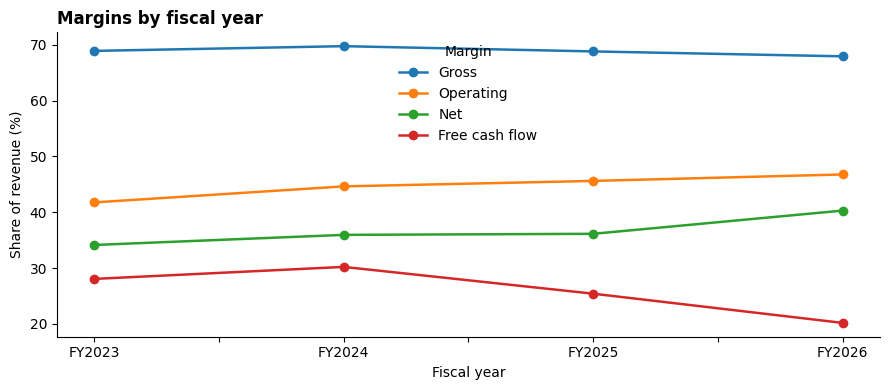

News summary: Microsoft is confronting a series of regulatory setbacks as the Trump administration suspends its participation in a green‑card program and freezes green cards for the firm and other IT companies, citing alleged fraud and a broader foreign‑worker crackdown [E1][E2][E6]. The suspension could impact hiring and compliance, and a report noted that Microsoft has been replacing laid‑off workers with foreign hires according to visa data [E4][E5]. Despite these challenges, the company earned a positive analyst rating, being named a Leader in the 2026 Gartner Magic Quadrant for Global Industrial AIoT Platforms [E3]. It also reported strong operational performance, posting 43% Azure growth, although its stock remains below its five‑year price‑to‑earnings multiple [E8]. Overall, the recent news tilts toward negative developments outweighing the positive accolades and growth metrics.
News feed errors: {}
Raw (125 records)


,id,title,summary,publisher,url,published_at,source_feed,duplicate_count,also_reported_by,event_type,relevance,impact,time_horizon
0,A001,It Now Takes $4.4B To Make the Forbes 400: See America's 10 Richest People,,MoneyLion,https://finance.yahoo.com/markets/stocks/articles/now-takes-4-4b-forbes-170028016.html,2026-10-11 17:00:28+00:00,yahoo_finance,1,[],None,None,None,None
1,A002,Does Everforth (EFOR) Embedding Screening in Workday Deepen Its Consulting-Led Platfor...,,Simply Wall St.,https://finance.yahoo.com/technology/ai/articles/does-everforth-efor-embedding-screeni...,2026-10-11 16:08:51+00:00,yahoo_finance,1,[],None,None,None,None
2,A003,What Could Microsoft (MSFT) Green Card Suspension Mean For Hiring And Compliance?,,Simply Wall St.,https://finance.yahoo.com/technology/articles/could-microsoft-msft-green-card-16083670...,2026-10-11 16:08:36+00:00,yahoo_finance,1,[],None,None,None,None
3,A004,America’s $6 Trillion Interest-Rate Trap Is Spreading Far Beyond the Bond Market — and...,,24/7 Wall St.,https://finance.yahoo.com/markets/stocks/articles/america-6-trillion-interest-rate-145...,2026-10-11 14:58:02+00:00,yahoo_finance,1,[],None,None,None,None
4,A005,Ray Dalio Warns Stocks Are Running Out of Room for Error — and AI Could Make It Worse,,24/7 Wall St.,https://finance.yahoo.com/markets/stocks/articles/ray-dalio-warns-stocks-running-14473...,2026-10-11 14:47:32+00:00,yahoo_finance,1,[],None,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...
120,A121,"Meta and Microsoft scale back internal use of Anthropic’s Claude, report says - Yahoo ...",,Yahoo Finance,https://news.google.com/rss/articles/CBMinwFBVV95cUxPSDd1S0xXV3o1YV9HTFVETHpnMHZad3lFS...,2026-10-05 18:58:42+00:00,google_news,1,[],None,None,None,None
121,A122,US suspends Microsoft and Adobe from visa programme amid fraud claims - Al Jazeera,,Al Jazeera,https://news.google.com/rss/articles/CBMiswFBVV95cUxOaWRMWUgwNjhseFRmckpXRXo0Ymw3OTZfb...,2026-10-08 18:40:00+00:00,google_news,1,[],None,None,None,None
122,A123,Rockwell Automation pairs AI with decades of shop floor know-how so workers can solve ...,,Microsoft Source,https://news.google.com/rss/articles/CBMi_AFBVV95cUxPVkxlWGxRMjdyUkstb09xUGdsajhQNDB6U...,2026-09-24 07:00:00+00:00,google_news,1,[],None,None,None,None
123,A124,Post-quantum authentication: Why organizations should start testing certificate ecosys...,,Microsoft,https://news.google.com/rss/articles/CBMi5gFBVV95cUxOandCWlZsdmVOQklPYTNlUUI2Q2hCaU40M...,2026-10-08 20:44:28+00:00,google_news,1,[],None,None,None,None


Clean (12 records)


,id,title,summary,publisher,url,published_at,source_feed,duplicate_count,also_reported_by,event_type,relevance,impact,time_horizon
0,A099,"The Trump administration is suspending Microsoft from a green card program, alleging f...",,AP News,https://news.google.com/rss/articles/CBMilwFBVV95cUxOSlNGOUJHbkJ0UXdETE9EUWMySjZkMWVzX...,2026-10-09 00:07:00+00:00,google_news,2,[NBC News],None,None,None,None
1,A088,"Trump's foreign worker crackdown comes for Microsoft, Adobe, IT firms",,Axios,https://news.google.com/rss/articles/CBMioAFBVV95cUxOTHBUeWVBdWg1NlRjbm0wVUJSSFlGeVRMc...,2026-10-08 18:13:38+00:00,google_news,2,[CNBC],None,None,None,None
2,A108,Microsoft named a Leader in the 2026 Gartner® Magic Quadrant™ for Global Industrial AI...,,Microsoft Azure,https://news.google.com/rss/articles/CBMi0gFBVV95cUxPT1JNOE9HUEdHLTFvdUV4TDZkTGtfMXdDZ...,2026-10-06 21:00:00+00:00,google_news,2,[],None,None,None,None
3,A003,What Could Microsoft (MSFT) Green Card Suspension Mean For Hiring And Compliance?,,Simply Wall St.,https://finance.yahoo.com/technology/articles/could-microsoft-msft-green-card-16083670...,2026-10-11 16:08:36+00:00,yahoo_finance,1,[],None,None,None,None
4,A080,Microsoft's Nadella says AI needs an ‘emergency brake’ that humans control,,CNBC,https://news.google.com/rss/articles/CBMijwFBVV95cUxOWllxOVA0bTc2VGhkSDNzOWpRT0pRZjU1d...,2026-10-10 20:59:28+00:00,google_news,1,[],None,None,None,None
5,A011,"Microsoft (MSFT) Posted 43% Azure Growth, Yet Trades Below Its Own Five-Year P/E. A Re...",,Insider Monkey,https://finance.yahoo.com/markets/stocks/articles/microsoft-msft-posted-43-azure-13264...,2026-10-10 17:11:42+00:00,yahoo_finance,1,[],None,None,None,None
6,A014,Microsoft vs. Alphabet: Which AI Cloud Stock Is Cheaper After the Capital Spending?,,Insider Monkey,https://finance.yahoo.com/technology/ai/articles/microsoft-vs-alphabet-ai-cloud-212027...,2026-10-10 15:20:27+00:00,yahoo_finance,1,[],None,None,None,None
7,A077,Vance says Microsoft replaced laid-off workers with foreign hires. Here’s what the vis...,,CNBC,https://news.google.com/rss/articles/CBMif0FVX3lxTE1UNjF1bGo2aXg5SldWVzhNbHBfSzZYbkpyY...,2026-10-10 14:22:23+00:00,google_news,1,[],None,None,None,None
8,A015,"Microsoft Stock Has Grown Roughly 15-Fold Since Satya Nadella Became CEO in 2014, a 27...",,Motley Fool,https://finance.yahoo.com/markets/stocks/articles/microsoft-stock-grown-roughly-15-141...,2026-10-10 14:15:00+00:00,yahoo_finance,1,[],None,None,None,None
9,A019,Microsoft Plus 2 Elite Defensive Stocks,,Simply Wall St.,https://finance.yahoo.com/markets/stocks/articles/microsoft-plus-2-elite-defensive-101...,2026-10-10 10:12:09+00:00,yahoo_finance,1,[],None,None,None,None


Classified (12 records)


,id,title,summary,publisher,url,published_at,source_feed,duplicate_count,also_reported_by,event_type,relevance,impact,time_horizon
0,A099,"The Trump administration is suspending Microsoft from a green card program, alleging f...",,AP News,https://news.google.com/rss/articles/CBMilwFBVV95cUxOSlNGOUJHbkJ0UXdETE9EUWMySjZkMWVzX...,2026-10-09 00:07:00+00:00,google_news,2,[NBC News],regulatory_legal,high,negative,medium_term
1,A088,"Trump's foreign worker crackdown comes for Microsoft, Adobe, IT firms",,Axios,https://news.google.com/rss/articles/CBMioAFBVV95cUxOTHBUeWVBdWg1NlRjbm0wVUJSSFlGeVRMc...,2026-10-08 18:13:38+00:00,google_news,2,[CNBC],regulatory_legal,high,negative,medium_term
2,A108,Microsoft named a Leader in the 2026 Gartner® Magic Quadrant™ for Global Industrial AI...,,Microsoft Azure,https://news.google.com/rss/articles/CBMi0gFBVV95cUxPT1JNOE9HUEdHLTFvdUV4TDZkTGtfMXdDZ...,2026-10-06 21:00:00+00:00,google_news,2,[],analyst_rating,high,positive,short_term
3,A003,What Could Microsoft (MSFT) Green Card Suspension Mean For Hiring And Compliance?,,Simply Wall St.,https://finance.yahoo.com/technology/articles/could-microsoft-msft-green-card-16083670...,2026-10-11 16:08:36+00:00,yahoo_finance,1,[],regulatory_legal,high,negative,medium_term
4,A080,Microsoft's Nadella says AI needs an ‘emergency brake’ that humans control,,CNBC,https://news.google.com/rss/articles/CBMijwFBVV95cUxOWllxOVA0bTc2VGhkSDNzOWpRT0pRZjU1d...,2026-10-10 20:59:28+00:00,google_news,1,[],market_commentary,medium,neutral,short_term
5,A011,"Microsoft (MSFT) Posted 43% Azure Growth, Yet Trades Below Its Own Five-Year P/E. A Re...",,Insider Monkey,https://finance.yahoo.com/markets/stocks/articles/microsoft-msft-posted-43-azure-13264...,2026-10-10 17:11:42+00:00,yahoo_finance,1,[],market_commentary,medium,positive,short_term
6,A014,Microsoft vs. Alphabet: Which AI Cloud Stock Is Cheaper After the Capital Spending?,,Insider Monkey,https://finance.yahoo.com/technology/ai/articles/microsoft-vs-alphabet-ai-cloud-212027...,2026-10-10 15:20:27+00:00,yahoo_finance,1,[],market_commentary,low,neutral,short_term
7,A077,Vance says Microsoft replaced laid-off workers with foreign hires. Here’s what the vis...,,CNBC,https://news.google.com/rss/articles/CBMif0FVX3lxTE1UNjF1bGo2aXg5SldWVzhNbHBfSzZYbkpyY...,2026-10-10 14:22:23+00:00,google_news,1,[],management,high,negative,short_term
8,A015,"Microsoft Stock Has Grown Roughly 15-Fold Since Satya Nadella Became CEO in 2014, a 27...",,Motley Fool,https://finance.yahoo.com/markets/stocks/articles/microsoft-stock-grown-roughly-15-141...,2026-10-10 14:15:00+00:00,yahoo_finance,1,[],market_commentary,low,neutral,short_term
9,A019,Microsoft Plus 2 Elite Defensive Stocks,,Simply Wall St.,https://finance.yahoo.com/markets/stocks/articles/microsoft-plus-2-elite-defensive-101...,2026-10-10 10:12:09+00:00,yahoo_finance,1,[],market_commentary,low,neutral,short_term


Events (8 records)


,id,article_id,event,event_date,entities,figures,dates_mentioned,risks,catalysts,event_type,relevance,impact,time_horizon,source,url,extraction_method
0,E1,A099,"The Trump administration is suspending Microsoft from a green card program, alleging f...",2026-10-09,"[Trump administration, Microsoft]",[],[],"[Potential loss of skilled immigration talent, Reputational risk from fraud allegations]",[],regulatory_legal,high,negative,medium_term,AP News,https://news.google.com/rss/articles/CBMilwFBVV95cUxOSlNGOUJHbkJ0UXdETE9EUWMySjZkMWVzX...,llm
1,E2,A088,"Trump's foreign worker crackdown targets Microsoft, Adobe, and other IT firms.",2026-10-08,"[Trump, Microsoft, Adobe, IT firms]",[],[],"[Potential hiring restrictions for foreign talent, Increased compliance costs]",[],regulatory_legal,high,negative,medium_term,Axios,https://news.google.com/rss/articles/CBMioAFBVV95cUxOTHBUeWVBdWg1NlRjbm0wVUJSSFlGeVRMc...,llm
2,E3,A108,Microsoft was named a Leader in the 2026 Gartner Magic Quadrant for Global Industrial ...,2026-10-06,[Gartner],[],[2026],[Pressure to maintain leadership position],[Enhanced market credibility and customer confidence],analyst_rating,high,positive,short_term,Microsoft Azure,https://news.google.com/rss/articles/CBMi0gFBVV95cUxPT1JNOE9HUEdHLTFvdUV4TDZkTGtfMXdDZ...,llm
3,E4,A003,Microsoft faces a green card suspension that could impact hiring and compliance.,2026-10-11,"[Microsoft, MSFT]",[],[],"[Potential hiring delays, Regulatory compliance risk]",[Resolution of the suspension],regulatory_legal,high,negative,medium_term,Simply Wall St.,https://finance.yahoo.com/technology/articles/could-microsoft-msft-green-card-16083670...,llm
4,E5,A077,"Vance says Microsoft replaced laid-off workers with foreign hires, according to visa d...",2026-10-10,[Vance],[],[],"[Reputational risk from perceived worker replacement, Potential labor or political bac...",[],management,high,negative,short_term,CNBC,https://news.google.com/rss/articles/CBMif0FVX3lxTE1UNjF1bGo2aXg5SldWVzhNbHBfSzZYbkpyY...,llm
5,E6,A070,The Trump administration froze green cards for Microsoft and other IT firms while prob...,2026-10-10,"[Trump administration, Microsoft]",[],[],"[Talent acquisition and staffing risk, Potential operational disruption due to immigra...",[],regulatory_legal,high,negative,medium_term,Reuters,https://news.google.com/rss/articles/CBMisAFBVV95cUxNenk2MHZ3TFhxRjBqU1pTRmZvNFRUYy1CS...,llm
6,E7,A080,Microsoft's Nadella said AI needs an ‘emergency brake’ that humans control.,2026-10-10,"[Microsoft, Nadella]",[],[],"[Uncontrolled AI could cause safety issues, Regulatory scrutiny over AI oversight]","[Human‑controlled safeguards may boost AI adoption, Emphasis on safety could increase ...",market_commentary,medium,neutral,short_term,CNBC,https://news.google.com/rss/articles/CBMijwFBVV95cUxOWllxOVA0bTc2VGhkSDNzOWpRT0pRZjU1d...,llm
7,E8,A011,"Microsoft posted 43% Azure growth, but its stock trades below its own five-year P/E.",2026-10-10,"[Microsoft, MSFT, Azure]",[43%],[],"[Growth sustainability risk, Potential valuation correction risk]","[Strong Azure growth could boost revenue, Discounted valuation may attract investors]",market_commentary,medium,positive,short_term,Insider Monkey,https://finance.yahoo.com/markets/stocks/articles/microsoft-msft-posted-43-azure-13264...,llm


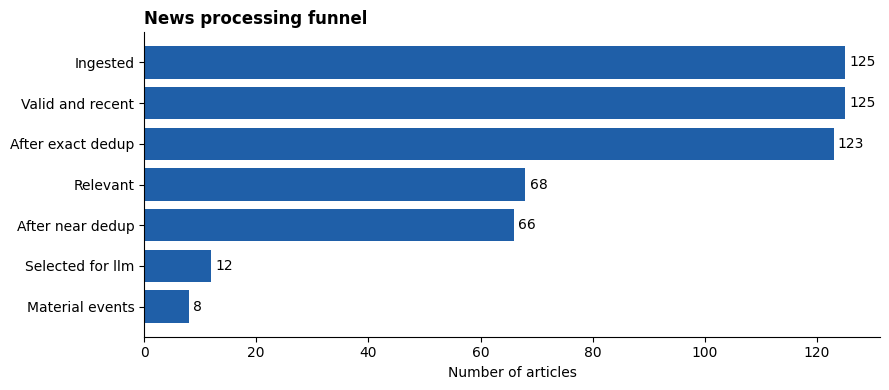

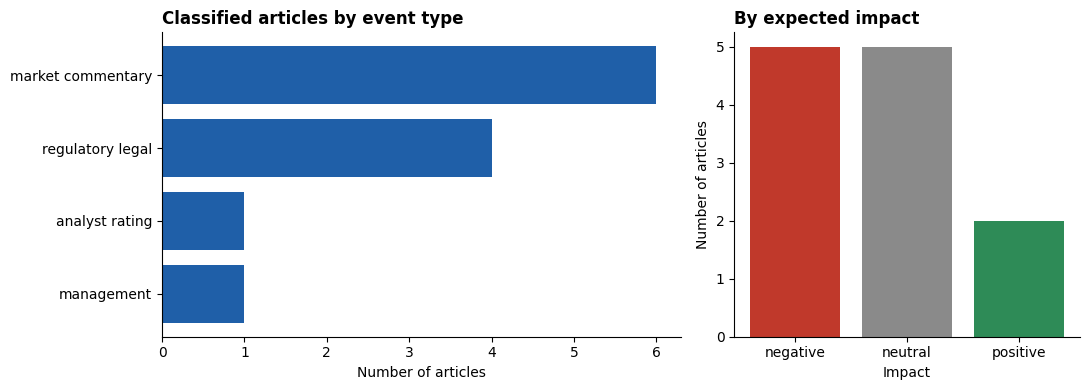

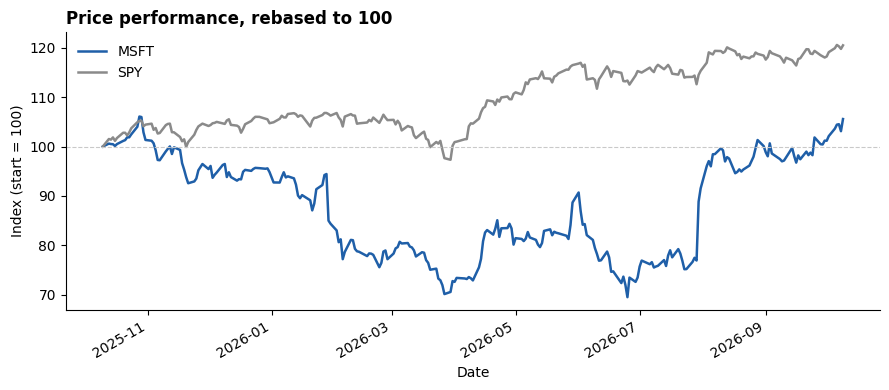

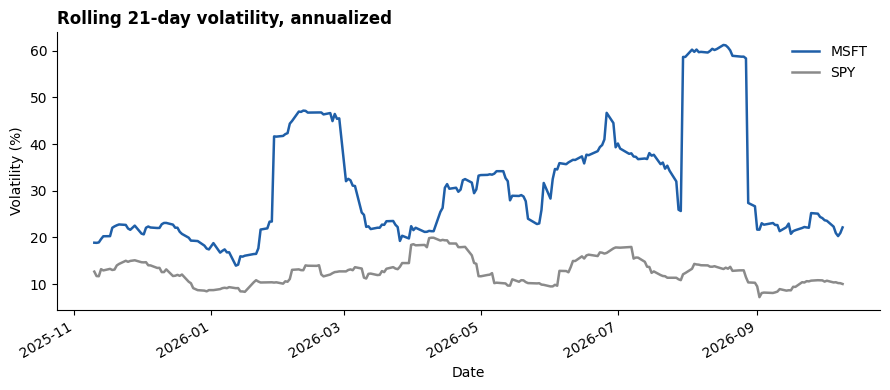

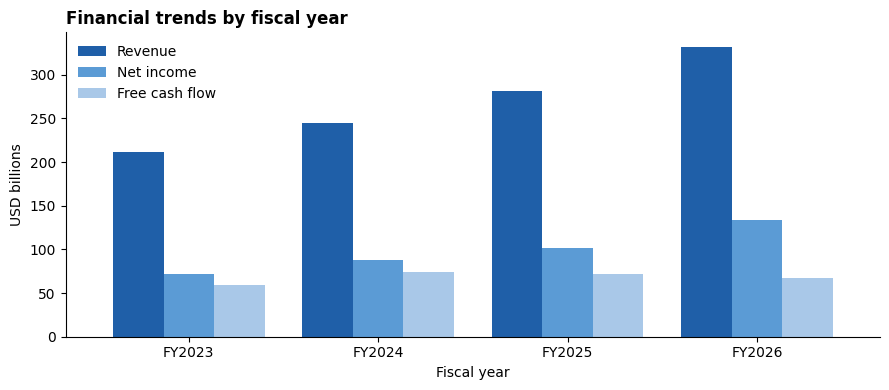

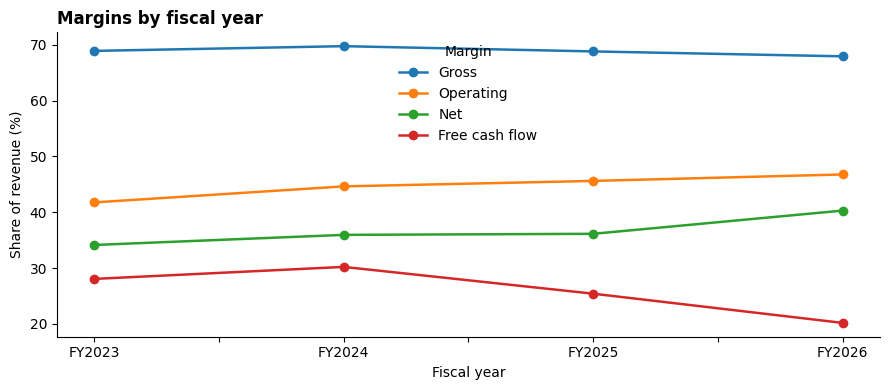

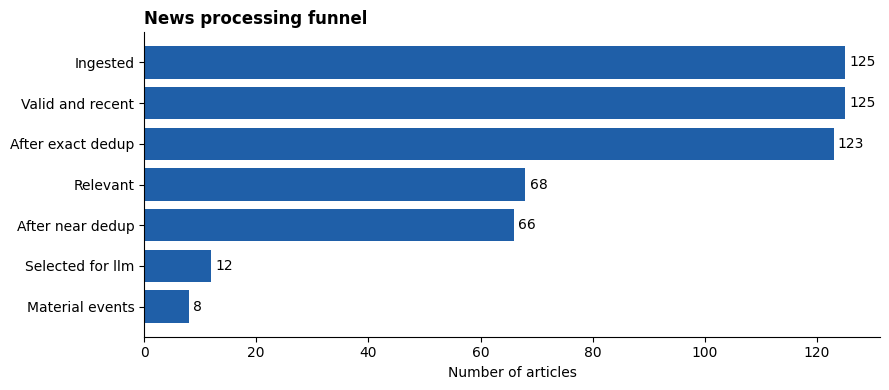

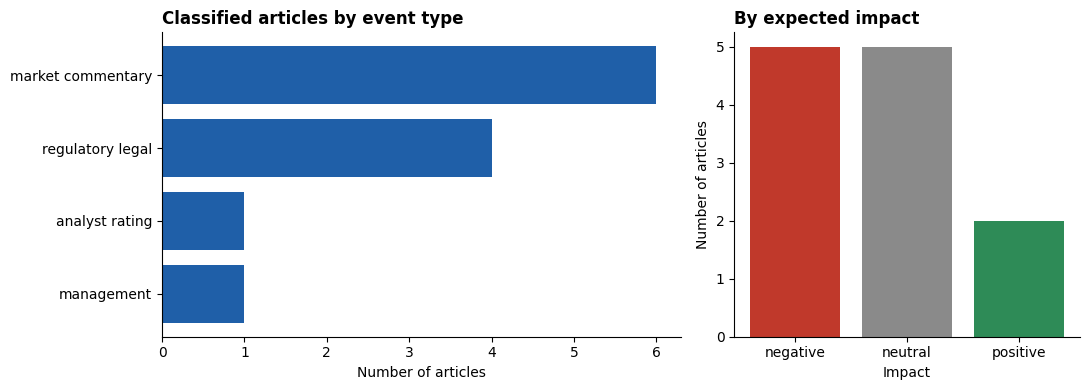

In [15]:
from src.visualizations import (
    plot_financial_trends, plot_margins, plot_news_categories, plot_news_funnel,
    plot_performance, plot_rolling_volatility,
)

comprehensive_state = rt.orchestrator.run('MSFT', 'Produce comprehensive investment research')
display(execution_table(comprehensive_state))
display(tool_log_table(comprehensive_state))
print('Coverage:', comprehensive_state.aggregated['coverage'])
profile = comprehensive_state.company_profile or {}
print('Company profile:', profile.get('name', 'unavailable'), '|', profile.get('sector'), '|', profile.get('currency'))
evidence_ids = {item.get('id') or item.get('evidence_id') for item in comprehensive_state.aggregated['evidence']}
cited_ids = {
    evidence_id
    for finding in comprehensive_state.aggregated['findings']
    for evidence_id in finding.get('evidence_ids', [])
}
unresolved_citations = sorted(cited_ids - evidence_ids)
print('Finding evidence references resolve:', not unresolved_citations, '| unresolved:', unresolved_citations)

visuals = comprehensive_state.aggregated['visualization_data']
market_visuals = visuals.get('market_agent', {})
if 'performance' in market_visuals:
    display(plot_performance(market_visuals['performance']))
    display(plot_rolling_volatility(market_visuals['rolling_volatility']))

earnings_visuals = visuals.get('earnings_agent', {})
if 'financial_trends' in earnings_visuals:
    display(plot_financial_trends(earnings_visuals['financial_trends'], earnings_visuals['currency']))
    display(plot_margins(earnings_visuals['margins']))

news_visuals = visuals.get('news_agent', {})
news_stages = news_visuals.get('stages', {})
if news_stages:
    print('News summary:', news_stages['summary']['summary'])
    print('News feed errors:', news_stages['feed_errors'])
    for stage in ('raw', 'clean', 'classified', 'events'):
        records = news_stages[stage]
        print(f'{stage.title()} ({len(records)} records)')
        rows = [record.model_dump() if callable(getattr(record, 'model_dump', None)) else record for record in records]
        display(pd.DataFrame(rows))
    display(plot_news_funnel(news_visuals['funnel']))
    category_values = []
    impact_values = []
    for article in news_stages['classified']:
        if isinstance(article, dict):
            event_type, impact = article.get('event_type'), article.get('impact')
        else:
            event_type, impact = article.event_type, article.impact
        if event_type:
            category_values.append(event_type)
        if impact:
            impact_values.append(impact)
    categories = pd.Series(category_values).value_counts().to_dict()
    impacts = pd.Series(impact_values).value_counts().to_dict()
    if categories or impacts:
        display(plot_news_categories(categories, impacts))
else:
    print('News stages unavailable:', [warning.message for warning in comprehensive_state.warnings])

Only the earnings and market tools were called; the news tool never ran because the plan did not select it.

## 5. Partial failure does not stop the workflow

The News subagent is replaced with one that raises an error. The other subagents still complete; the failure becomes a warning and a limitation for the report.

In [7]:
original_news_agent = rt.subagents.get('news_agent').fn

def failing_news_agent(state, tools, step):
    raise RuntimeError('simulated news API outage')

rt.subagents.attach('news_agent', failing_news_agent)
try:
    failed_run = rt.orchestrator.run('AAPL', 'Produce comprehensive investment research')
finally:
    rt.subagents.attach('news_agent', original_news_agent)

display(execution_table(failed_run)[['step_id', 'subagent', 'status', 'tool_calls', 'message']])
print('Coverage   :', failed_run.aggregated['coverage'])
print('Limitations:')
for item in failed_run.aggregated['limitations']:
    print('  -', item['agent'], ':', item['text'])
print('Errors     :', [w.message for w in failed_run.warnings if w.severity == 'error'])

,step_id,subagent,status,tool_calls,message
0,S1,market_agent,success,2,[STUB] market_agent executed 2/2 planned tool calls; no analysis performed.
1,S2,earnings_agent,success,1,[STUB] earnings_agent executed 1/1 planned tool calls; no analysis performed.
2,S3,news_agent,failed,0,RuntimeError: simulated news API outage


Coverage   : {'market_agent': 'success', 'earnings_agent': 'success', 'news_agent': 'failed'}
Limitations:
  - market_agent : Stub implementation: no real data was analysed.
  - earnings_agent : Stub implementation: no real data was analysed.
  - news_agent : news_agent did not complete (failed); no analysis available.
Errors     : ['Subagent failed: RuntimeError: simulated news API outage']


## 6. Hand-off to the Report Generator

`state.aggregated` is the single structure Engineer 3 consumes: per-agent status, findings, risks, limitations, de-duplicated evidence with ids, coverage, warnings and memories used. When `src/report_generator.py` exposes `run_report_pipeline(state)`, `build_runtime()` wires it in automatically.

In [8]:
agg = state.aggregated
print({k: (len(v) if isinstance(v, (list, dict)) else v) for k, v in agg.items() if k not in ('question',)})
print('Report pipeline:', rt.integration['report_pipeline'])

{'symbol': 'AAPL', 'company_profile': 3, 'agents': 2, 'coverage': 2, 'findings': 0, 'risks': 0, 'limitations': 2, 'evidence': 0, 'warnings': 1, 'memories_used': 0, 'aggregated_at': '2026-10-11T09:07:15+00:00'}
Report pipeline: missing
